# 01 · Mole balances and the ideal reactors

Everything starts with a balance on a species: in minus out plus generation equals accumulation. Applied
to a well-mixed tank with no flow it gives the batch reactor; with flow, the CSTR; to a thin slice of a tube,
the plug-flow reactor; to a slice of catalyst, the packed bed. This notebook derives the four design equations,
solves them for the course's first-order reaction, and compares the reactors on the same job.

**What you will learn**
- derive the batch, CSTR, PFR and PBR design equations from the general balance
- solve them for first-order kinetics
- size reactors for any rate law given as a function of conversion
- integrate a multi-species batch reactor numerically

**Before you start:** notebook 00  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import ideal, kinetics
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The general mole balance
$$F_{A0} - F_A + \int^V r_A\,dV = \frac{dN_A}{dt}$$
Batch (no flow): $dN_A/dt = r_A V$. CSTR (steady, well mixed): $V = (F_{A0} - F_A)/(-r_A)$. PFR (steady,
no axial mixing): $dF_A/dV = r_A$. PBR: $dF_A/dW = r_A'$ per mass of catalyst. Conversion $X = (F_{A0} - F_A)/F_{A0}$
turns each into an equation in $X$.

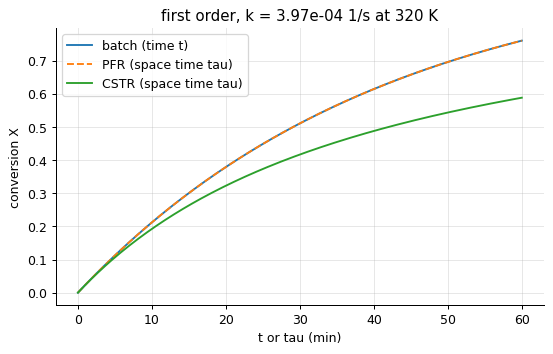

X = 0.5: batch/PFR needs   29.1 min; a CSTR needs tau =    41.9 min (1.4 x longer)
X = 0.9: batch/PFR needs   96.5 min; a CSTR needs tau =   377.4 min (3.9 x longer)
X = 0.99: batch/PFR needs  193.1 min; a CSTR needs tau =  4151.1 min (21.5 x longer)


In [2]:
k = kinetics.arrhenius(5.0e7, 68e3, 320.0)
C_A0 = 2500.0
tau = np.linspace(0, 3600, 200)
fig, ax = plt.subplots()
ax.plot(tau / 60, ideal.batch_conversion_first_order(k, tau), label="batch (time t)")
ax.plot(tau / 60, [ideal.pfr_conversion_first_order(k, t) for t in tau], "--", label="PFR (space time tau)")
ax.plot(tau / 60, [ideal.cstr_conversion_first_order(k, t) for t in tau], label="CSTR (space time tau)")
ax.set(xlabel="t or tau (min)", ylabel="conversion X", title=f"first order, k = {k:.2e} 1/s at 320 K"); ax.legend(); plt.show()
for X in (0.5, 0.9, 0.99):
    t_b = ideal.batch_time_nth_order(k, C_A0, X, 1)
    print(f"X = {X}: batch/PFR needs {t_b/60:6.1f} min; a CSTR needs tau = {X/(k*(1-X))/60:7.1f} min ({X/(k*(1-X))/t_b:.1f} x longer)")

The batch reactor and the PFR obey the same equation - time in one is space time in the other - and both
beat the CSTR for a positive-order reaction, because the CSTR runs entirely at the low outlet concentration.
At 99 % conversion the CSTR needs twenty times the residence time: the penalty grows without bound as X
approaches 1.

## Design equations for any rate law

In [3]:
rate = lambda X: k * C_A0 * (1 - X)                    # -r_A(X) in mol/(m3 s)
F_A0 = 2.0                                              # mol/s (v0 = 0.8 L/s of 2.5 M feed)
for X in (0.6, 0.9):
    print(f"X = {X}: V_CSTR = {ideal.cstr_volume(F_A0, X, rate):.3f} m3, V_PFR = {ideal.pfr_volume(F_A0, X, rate):.3f} m3")
V = 2.0
print(f"\na 2 m3 reactor: CSTR reaches X = {ideal.cstr_conversion(F_A0, V, rate):.3f}, PFR X = {ideal.pfr_conversion(F_A0, V, rate):.3f}")
prof = ideal.pfr_profile(F_A0, V, rate)
print("PFR conversion at 25 %, 50 %, 75 % of the length:", np.round(np.interp([0.5, 1.0, 1.5], prof["V"], prof["X"]), 3))

X = 0.6: V_CSTR = 3.019 m3, V_PFR = 1.844 m3
X = 0.9: V_CSTR = 18.114 m3, V_PFR = 4.634 m3

a 2 m3 reactor: CSTR reaches X = 0.498, PFR X = 0.630
PFR conversion at 25 %, 50 %, 75 % of the length: [0.22  0.392 0.525]


With the rate given as a function of conversion, the library sizes either reactor by quadrature or root
finding, and gives the profile along a PFR - which shows the first quarter of the reactor doing more than the
last: rates fall as reactant is consumed.

## A numerical reactor for any set of species

In [4]:
rates = {"A": lambda C: -k * C["A"], "B": lambda C: k * C["A"]}
b = ideal.batch(rates, {"A": C_A0, "B": 0.0}, np.linspace(0, 3600, 7))
print(pd.DataFrame({"t (min)": b["t"] / 60, "C_A": b["A"], "C_B": b["B"], "C_A + C_B": b["A"] + b["B"]}).round(1).to_string(index=False))
c = ideal.cstr_steady(rates, {"A": C_A0, "B": 0.0}, tau=1200.0)
print(f"\nCSTR with tau = 20 min: C_A = {c['A']:.1f}, C_B = {c['B']:.1f} mol/m3 (X = {1 - c['A']/C_A0:.3f}; analytic {ideal.cstr_conversion_first_order(k, 1200.0):.3f})")

 t (min)    C_A    C_B  C_A + C_B
     0.0 2500.0    0.0     2500.0
    10.0 1969.5  530.5     2500.0
    20.0 1551.6  948.4     2500.0
    30.0 1222.4 1277.6     2500.0
    40.0  963.0 1537.0     2500.0
    50.0  758.7 1741.3     2500.0
    60.0  597.7 1902.3     2500.0

CSTR with tau = 20 min: C_A = 1692.6, C_B = 807.4 mol/m3 (X = 0.323; analytic 0.323)


When rate laws are given in concentrations and there are several species, the reactors are integrated
numerically; the analytic cases above are then checks, and the atom balance (A + B constant) is the
sanity test that costs nothing and catches most mistakes.

## The four reactors in one table

In [5]:
rows = [("batch", "dN_A/dt = r_A V", "unsteady, no flow", "small volumes, pharmaceuticals, polymers, trials"),
        ("CSTR", "V = F_A0 X / (-r_A)", "steady, perfectly mixed", "liquid phase, fermentation, easy temperature control"),
        ("PFR", "dX/dV = -r_A / F_A0", "steady, no axial mixing", "gas phase, high conversion, large throughput"),
        ("PBR", "dX/dW = -r_A' / F_A0", "steady, catalyst mass W", "heterogeneous catalysis: most of the chemical industry")]
print(pd.DataFrame(rows, columns=["reactor", "design equation", "assumptions", "typical use"]).to_string(index=False))

reactor      design equation             assumptions                                            typical use
  batch      dN_A/dt = r_A V       unsteady, no flow       small volumes, pharmaceuticals, polymers, trials
   CSTR  V = F_A0 X / (-r_A) steady, perfectly mixed   liquid phase, fermentation, easy temperature control
    PFR  dX/dV = -r_A / F_A0 steady, no axial mixing           gas phase, high conversion, large throughput
    PBR dX/dW = -r_A' / F_A0 steady, catalyst mass W heterogeneous catalysis: most of the chemical industry


Four idealisations, and the rest of the course: how the rate depends on concentration and temperature
(notebooks 03, 05), how to choose and combine reactors (02, 04), what happens with several reactions (06),
with heat (07-09), with catalysts (10-13), and when the mixing is not ideal (14-15).

## Inside the algorithm: the PFR design integral

In [6]:
from scipy import integrate
val, _ = integrate.quad(lambda x: 1 / (k * C_A0 * (1 - x)), 0, 0.9)
print("by hand: V =", F_A0 * val, "m3; library:", ideal.pfr_volume(F_A0, 0.9, rate))

by hand: V = 4.634255213452891 m3; library: 4.634255213452891


## Exercises
1. A liquid-phase reaction with -r_A = k C_A^0.5 (k = 0.05 (mol/m3)^0.5/s, C_A0 = 400 mol/m3, F_A0 = 1 mol/s) is to reach 90 % conversion. Size a CSTR and a PFR, and explain why the ratio is smaller than for first order.
2. For a zero-order reaction, show numerically that the CSTR and PFR volumes are equal for any conversion, and explain why with the Levenspiel picture.
3. **Implement it yourself:** write the CSTR balance for a first-order reaction as a residual function and solve it with brentq for X at tau = 20 min; compare with `ideal.cstr_conversion_first_order`.